# EWELD C24 — Valutazione robusta multiutente
Questo notebook affronta le due mancanze principali emerse nella revisione del progetto per un articolo scientifico:

1. **Valutazione statisticamente debole.** Finora i test duravano 2 giorni e cadevano in periodi festivi.
   Qui ogni modello viene valutato su **un anno intero di origini rolling** (una previsione a 48 ore ogni 48 ore,
   blocchi non sovrapposti), con **refit periodico**, **più seed** per le reti e **test statistici**:
   Diebold-Mariano (per utente e sul pannello), Friedman + Nemenyi con diagramma delle differenze critiche,
   Wilcoxon con correzione di Holm e intervalli di confidenza bootstrap a blocchi.
2. **Un solo utente per i modelli profondi.** Qui tutti i modelli girano su **tutte le utenze ammesse**, con un
   criterio di ammissibilità basato **solo sulla disponibilità dei dati**, fissato prima di vedere gli errori.
   Si misura anche quanto sarebbe stato ottimistico valutare soltanto l'utente "migliore" in sviluppo (es. U155).

Il motore è in `eweld_robusta.py`, che riusa dati, calendario e worker di `eweld_multiutente.py` senza modificarlo.
I backend girano in processi isolati sulla CPU. I parziali vengono salvati: se l'esecuzione si interrompe,
rilanciando le celle con lo stesso profilo i lavori già completati non vengono ripetuti.

## 1. Configurazione (fissata prima degli esperimenti)
- `smoke`: verifica tecnica in pochi minuti (3 utenti, 8 origini, 2 epoche). **Non produce risultati utilizzabili.**
- `rapido`: anno completo, refit ogni 91 giorni, 3 seed, senza TFT. Stima: 20–40 minuti su questo Mac
  (misurati circa 50 s per addestramento del GRU globale, 45 s per XGBoost globale, 0,5 s per origine SARIMAX).
- `completo`: anno completo, refit ogni 28 giorni, 5 seed, TFT incluso. Stima: alcune ore; il TFT è il più lento.

Il periodo di test predefinito è il **2020** (training sui 365 giorni precedenti ogni refit). È coerente con il
protocollo del benchmark multiutente, che aveva riservato origini del 2020 come periodo finale.
Il 2020 contiene Capodanno lunare e lockdown COVID: c'è un'analisi di sensibilità che esclude quella finestra.
Con i criteri attuali nel 2020 entrano **11 utenze su 23**. Per una replica si può impostare `TEST_YEAR = 2019`,
che ammette un insieme di utenze in parte diverso.

**Ispezioni precedenti da dichiarare nella relazione:** il notebook dei modelli profondi ha già esaminato
1–2 gennaio 2020 su U155; il pilota multiutente ha usato origini di sviluppo nel 2019.

In [1]:
from pathlib import Path
import sys, json, pickle, importlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd()/'datasets', Path.cwd()) if (p/'EWELD').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import eweld_multiutente as bench
import eweld_robusta as rob
bench = importlib.reload(bench); rob = importlib.reload(rob)

PROFILE = 'completo'      # 'smoke' | 'rapido' | 'completo'
TEST_YEAR = 2020
FOCUS_USER = 'U155'     # utente scelto nel notebook dei modelli profondi
ANOMALY = ('2020-01-10', '2020-03-31')   # Capodanno lunare 2020 + lockdown COVID (sensibilità)
assert PROFILE in ('smoke', 'rapido', 'completo')

CFG = dict(horizon=48, lookback=168, train_days=365, val_blocks=7, stride=24,
           max_samples_per_user=256, min_samples_per_user=30,
           test_start=f'{TEST_YEAR}-01-01', test_end=f'{TEST_YEAR}-12-31', origin_step=48,
           refit_days={'smoke': 7, 'rapido': 91, 'completo': 28}[PROFILE],
           seeds={'smoke': [42, 123], 'rapido': [42, 123, 2026], 'completo': [42, 123, 2026, 7, 99]}[PROFILE],
           min_train_coverage=.95, min_origin_coverage=.90, max_train_zero_share=.50,
           threads=2, parallel_jobs=6, batch_size=32,
           max_epochs=2 if PROFILE == 'smoke' else 100, patience=1 if PROFILE == 'smoke' else 12,
           sarimax_order=[1, 1, 1], sarimax_seasonal=[1, 0, 1, 24],
           sarimax_train_days=14 if PROFILE == 'smoke' else 60,
           sarimax_maxiter=5 if PROFILE == 'smoke' else 50,
           max_origins=8 if PROFILE == 'smoke' else None, max_refits=None)
if PROFILE == 'smoke':
    CFG.update(max_samples_per_user=32, min_samples_per_user=10)

GRIDS = {
    'XGBoost': [dict(n_estimators=100, max_depth=4, learning_rate=.05),
                dict(n_estimators=200, max_depth=4, learning_rate=.05)],
    'LightGBM': [dict(n_estimators=200, num_leaves=15, learning_rate=.05),
                 dict(n_estimators=200, num_leaves=31, learning_rate=.03)],
    'GRU': [dict(hidden=32, layers=1, lr=.001), dict(hidden=64, layers=1, lr=.001)],
    'TFT': [dict(hidden=16, layers=1, lr=.001), dict(hidden=32, layers=2, lr=.001)],
}
if PROFILE == 'smoke':
    GRIDS = {m: g[:1] for m, g in GRIDS.items()}
    GRIDS['XGBoost'] = [dict(n_estimators=20, max_depth=3, learning_rate=.1)]
    GRIDS['LightGBM'] = [dict(n_estimators=20, num_leaves=7, learning_rate=.1)]
    GRIDS['TFT'] = [dict(hidden=8, layers=1, lr=.001)]
SPECS = [dict(name='XGBoost_locale', model='XGBoost', strategy='locale'),
         dict(name='XGBoost_globale', model='XGBoost', strategy='globale'),
         dict(name='LightGBM_globale', model='LightGBM', strategy='globale'),
         dict(name='GRU_globale', model='GRU', strategy='globale')]
if PROFILE in ('smoke', 'completo'):
    SPECS.append(dict(name='TFT_globale', model='TFT', strategy='globale'))
for s in SPECS:
    s['grid'] = GRIDS[s['model']]
RUN_SARIMAX = True
RUN_ML = True
REFERENCE = 'Naive24'    # riferimento per skill, DM e bootstrap: il più forte tra le baseline
# I file delle analisi vanno in una sottocartella per riferimento; previsioni e parziali sono condivisi.
print('Profilo', PROFILE, '| sistemi appresi:', [s['name'] for s in SPECS], '| seed reti:', CFG['seeds'])

Profilo completo | sistemi appresi: ['XGBoost_locale', 'XGBoost_globale', 'LightGBM_globale', 'GRU_globale', 'TFT_globale'] | seed reti: [42, 123, 2026, 7, 99]


## 2. Utenze ammesse e calendario delle origini
Un'utenza entra se, nei 365 giorni prima del test, ha almeno il 95% delle ore e **non più del 50% di ore a zero**,
e se ha almeno il 90% di origini di test valutabili (168 ore di contesto e 48 di target senza buchi).
Il criterio sugli zeri usa solo il training: esclude contatori fermi tutto l'anno (es. U156 sempre a zero,
U134 a zero nel 97% delle ore del 2019), su cui MASE e skill non sono definiti. Nessuna esclusione dipende dagli errori.
Tutti i modelli sono valutati sulle **stesse coppie utente/origine**.

In [2]:
panel = bench.load_panel(ROOT)
city = bench.locations(ROOT, panel)
audit = rob.eligibility(panel, CFG)
USERS = sorted(audit.loc[audit.eligible, 'user'])
if PROFILE == 'smoke':
    USERS = USERS[:3]
ORIGINS = rob.test_origins(CFG)
REFITS = rob.refit_dates(CFG, ORIGINS)
refit_of = rob.assign_refit(ORIGINS, REFITS)
origins_by_user = {u: [o for o in ORIGINS if rob.window_ok(panel[u], o, CFG)] for u in USERS}

display(audit.sort_values('user').style.format({'train_coverage': '{:.1%}', 'train_zero_share': '{:.0%}', 'origin_coverage': '{:.1%}'}))
print(f'Utenze ammesse: {len(USERS)}/{len(panel)}:', USERS)
print(f'Origini di test: {len(ORIGINS)} ({ORIGINS[0]:%d/%m/%Y} → {ORIGINS[-1]:%d/%m/%Y}), refit: {len(REFITS)}')
print('Coppie utente/origine valutate:', sum(map(len, origins_by_user.values())))
if FOCUS_USER not in USERS:
    print(f'Attenzione: {FOCUS_USER} non è nel pannello con questo profilo/anno.')
assert len(USERS) >= (3 if PROFILE == 'smoke' else 5), 'Pannello troppo piccolo per i test di Friedman.'

PROTOCOL = dict(profile=PROFILE, config=CFG, specs=SPECS, users=USERS,
                origins=[str(o) for o in ORIGINS], refits=[str(r) for r in REFITS])
OUT = ROOT/'risultati_valutazione_robusta'/f'{PROFILE}_{TEST_YEAR}'
OUT.mkdir(parents=True, exist_ok=True)
saved = OUT/'protocollo.json'
# Il riferimento riguarda solo l'analisi, non l'addestramento: è escluso dal confronto del protocollo.
previous = json.loads(saved.read_text()) if saved.exists() else None
if previous is not None:
    previous.pop('reference', None)
if previous is not None and previous != json.loads(json.dumps(PROTOCOL)):
    raise RuntimeError(f'{saved} ha un protocollo diverso: cambiare cartella invece di mescolare risultati.')
saved.write_text(json.dumps(PROTOCOL, indent=2))
audit.to_csv(OUT/'ammissibilita.csv', index=False)
ANA = OUT/f'analisi_{REFERENCE}'
ANA.mkdir(exist_ok=True)
print('Output:', OUT, '| analisi:', ANA.name)

,user,train_coverage,train_zero_share,valid_origins,origin_coverage,eligible
0,U134,100.0%,97%,182,99.5%,False
1,U135,100.0%,0%,183,100.0%,True
2,U136,100.0%,41%,183,100.0%,True
3,U137,100.0%,7%,183,100.0%,True
4,U138,100.0%,0%,86,47.0%,False
5,U139,0.0%,100%,0,0.0%,False
6,U140,1.8%,1%,0,0.0%,False
7,U141,100.0%,0%,183,100.0%,True
8,U142,100.0%,0%,183,100.0%,True
9,U143,100.0%,7%,183,100.0%,True


Utenze ammesse: 11/23: ['U135', 'U136', 'U137', 'U141', 'U142', 'U143', 'U144', 'U147', 'U148', 'U151', 'U155']
Origini di test: 183 (01/01/2020 → 30/12/2020), refit: 14
Coppie utente/origine valutate: 2013
Output: /Users/andrea.quarta/workspace_personal/progetto_corso_perfezionamento/datasets/risultati_valutazione_robusta/completo_2020 | analisi: analisi_Naive24


In [3]:
# Controllo causale: alterare i valori futuri non deve cambiare gli ingressi del modello.
u, o = USERS[0], origins_by_user[USERS[0]][0]
params = {u: rob.scaling(panel[u].loc[o-pd.Timedelta(365, unit='D'):o-pd.Timedelta(1, unit='h')])}
a, _ = rob.prediction_samples(panel, {u: [o]}, USERS, city, params, CFG, False)
altered = {**panel, u: panel[u].copy()}
altered[u].loc[o:] = -999999.
b, _ = rob.prediction_samples(altered, {u: [o]}, USERS, city, params, CFG, False)
assert all(np.array_equal(a[k], b[k]) for k in ('x', 'f', 'static', 'y'))
print('Controllo causale superato: il futuro non entra negli ingressi né nel target inviato al worker.')

Controllo causale superato: il futuro non entra negli ingressi né nel target inviato al worker.


## 3. Previsioni
### 3.1 Baseline
Naive giornaliero (ultime 24 ore), naive settimanale (stessa ora di 7 giorni prima) e media stagionale delle
ultime 4 settimane. Sono economiche e spesso difficili da battere sulle serie industriali.

In [4]:
rows = rob.baseline_forecasts(panel, origins_by_user, CFG)
print('Previsioni baseline:', len(rows))

Previsioni baseline: 6039


### 3.2 SARIMAX
SARIMAX(1,1,1)(1,0,1)<sub>24</sub> con Fourier settimanali e indicatore del Capodanno lunare: è la configurazione
del Capitolo 3, che aveva vinto la walk-forward. Si stima su 60 giorni a ogni refit; a ogni origine il filtro
viene riapplicato ai 60 giorni precedenti **senza ristimare i parametri**. Se una stima fallisce si usa il naive
settimanale e il caso viene contato (colonna `status`), invece di scartare l'utente.

In [5]:
cache = OUT/'sarimax.pkl'
if RUN_SARIMAX:
    if cache.exists():
        sarimax_rows = pickle.loads(cache.read_bytes())
    else:
        t = time.perf_counter()
        sarimax_rows = rob.run_sarimax(panel, origins_by_user, refit_of, CFG, workers=CFG['parallel_jobs'])
        cache.write_bytes(pickle.dumps(sarimax_rows))
        print(f'SARIMAX: {time.perf_counter()-t:.0f}s')
    rows += sarimax_rows
    display(pd.Series([r['status'] for r in sarimax_rows]).value_counts().rename('esiti SARIMAX'))

ok    2013
Name: esiti SARIMAX, dtype: int64

### 3.3 Modelli appresi
- **Tuning una sola volta, prima del test:** fit sui 365 giorni prima del test meno gli ultimi 14, validazione sulle
  7 origini interne degli ultimi 14 giorni. Per le reti si conserva anche l'epoca migliore. Il tuning usa il primo
  seed. La configurazione resta **congelata per tutto l'anno**.
- **Refit periodico:** a ogni data di refit il modello si riaddestra sui 365 giorni precedenti e prevede tutte le
  origini fino al refit successivo. Gli ingressi includono le osservazioni già arrivate, mai quelle future.
- **Seed:** le reti girano con tutti i seed del profilo; gli alberi con un seed (sono quasi deterministici).
- **Strategie:** XGBoost locale e globale; LightGBM, GRU e TFT globali (identità e città come statiche).

In [6]:
tuning, dev_scores = {}, {}
if RUN_ML:
    tuning_path = OUT/'tuning.json'
    tuning = json.loads(tuning_path.read_text()) if tuning_path.exists() else {}
    for spec in SPECS:
        if spec['name'] not in tuning:
            t = time.perf_counter()
            tuning[spec['name']] = rob.tune_spec(spec, panel, USERS, city, CFG)
            tuning_path.write_text(json.dumps(tuning, indent=2, default=str))
            print(f"tuning {spec['name']}: {time.perf_counter()-t:.0f}s")
        t = time.perf_counter()
        rows += rob.run_spec(spec, tuning[spec['name']], panel, USERS, city, origins_by_user, refit_of, CFG,
                             OUT/'parziali')
        print(f"{spec['name']} completato in {time.perf_counter()-t:.0f}s")
print('Previsioni totali:', len(rows))

XGBoost_locale completato in 0s
XGBoost_globale completato in 0s
LightGBM_globale completato in 0s


GRU_globale completato in 0s


TFT_globale completato in 0s
Previsioni totali: 34221


### 3.4 Esperimenti aggiuntivi: combinazione con Naive24 e indicatori di fermo
Sull'anno, Naive24 e LightGBM globale sono risultati alla pari, ma vincono su utenti diversi: Naive24 dove ci
sono fermi lunghi, LightGBM dove l'impianto lavora con regolarità. Si provano quattro varianti:

- **`LightGBM_fermi_globale`**: LightGBM con sei indicatori di fermo calcolati sul solo contesto passato (quota di
  ore a basso consumo nelle ultime 24 e 168 ore, stato dell'ultima ora, ore dall'ultimo fermo e dall'ultima ora
  di lavoro, numero di transizioni). Un'ora è "bassa" se non supera il 5% del consumo medio di training.
- **`LightGBM_residuo_globale`**: stesse feature, ma il modello impara la **correzione a Naive24**
  (target = valore − naive giornaliero). Se non trova nulla di utile, ricade su Naive24.
- **`Comb_media_LightGBM_globale`**: media 50/50 tra LightGBM e Naive24, senza parametri.
- **`Comb_adattiva_LightGBM_globale`**: per ogni utente, il peso di LightGBM (0, 0,25, 0,5, 0,75, 1) è scelto
  sul MAE delle ultime 15 origini già osservate (30 giorni). Usa solo il passato.

Tuning e refit seguono lo stesso protocollo dei modelli principali (configurazione congelata prima del test).

**Attenzione per la relazione:** queste varianti sono state ideate **dopo** aver visto i risultati del 2020.
Una conferma pulita richiede di ripeterle su un anno diverso (es. `TEST_YEAR = 2019`) senza modificarle.


In [7]:
RUN_EXPERIMENTS = True
EXTRA_SPECS = [dict(name='LightGBM_fermi_globale', model='LightGBM', strategy='globale',
                    grid=[dict(g, fermi=True) for g in GRIDS['LightGBM']]),
               dict(name='LightGBM_residuo_globale', model='LightGBM', strategy='globale',
                    grid=[dict(g, fermi=True, residuo=True) for g in GRIDS['LightGBM']])]
if RUN_EXPERIMENTS:
    # Protocollo separato: gli esperimenti non alterano quello dei modelli principali.
    (OUT/'protocollo_esperimenti.json').write_text(json.dumps(EXTRA_SPECS, indent=2))
    exp_path = OUT/'tuning_esperimenti.json'
    tuning_exp = json.loads(exp_path.read_text()) if exp_path.exists() else {}
    for spec in EXTRA_SPECS:
        if spec['name'] not in tuning_exp:
            t = time.perf_counter()
            tuning_exp[spec['name']] = rob.tune_spec(spec, panel, USERS, city, CFG)
            exp_path.write_text(json.dumps(tuning_exp, indent=2, default=str))
            print(f"tuning {spec['name']}: {time.perf_counter()-t:.0f}s")
        t = time.perf_counter()
        rows += rob.run_spec(spec, tuning_exp[spec['name']], panel, USERS, city, origins_by_user, refit_of, CFG,
                             OUT/'parziali')
        print(f"{spec['name']} completato in {time.perf_counter()-t:.0f}s")
    tuning.update(tuning_exp)  # anche le varianti entrano nell'analisi della selezione dell'utente
    comb = rob.combine_forecasts(rows, 'LightGBM_globale', 'Naive24', CFG)
    rows += comb
    weights = pd.Series([r['status'] for r in comb if r['model'].startswith('Comb_adattiva')]).value_counts().sort_index()
    display(weights.rename('pesi scelti per LightGBM (combinazione adattiva)').to_frame())
print('Previsioni totali:', len(rows))

LightGBM_fermi_globale completato in 0s
LightGBM_residuo_globale completato in 0s


,pesi scelti per LightGBM (combinazione adattiva)
peso_0.00,516
peso_0.25,217
peso_0.50,439
peso_0.75,419
peso_1.00,422


Previsioni totali: 42273


### 3.5 Modelli pre-addestrati zero-shot: TimesFM
Due modelli *foundation* di Google, usati **senza addestramento né tuning** sui dati EWELD:
- **`TimesFM3_zeroshot`**: TimesFM 3.0 (agosto 2026), con backend MLX sulla **GPU Apple**.
  I pesi hanno licenza `timesfm-non-commercial-license-v1.0`: uso di ricerca consentito, va citata.
- **`TimesFM25_zeroshot`**: TimesFM 2.5 (200M parametri, Apache 2.0), backend PyTorch sulla CPU
  (il backend PyTorch supporta solo CUDA o CPU, non la GPU Apple).

A ogni origine il modello riceve le **2.048 ore precedenti** (circa 12 settimane) del solo consumo, senza
calendario né altre variabili; i buchi nel contesto sono interpolati linearmente. La lunghezza del contesto è
fissata qui, prima di vedere i risultati. La previsione puntuale è la mediana; si salvano anche i decili
(0,1–0,9) per la valutazione probabilistica qui sotto.

I modelli girano in un venv separato (`.venv_timesfm`) tramite `eweld_timesfm.py`; i pesi stanno in
`~/.cache/eweld_timesfm` e vanno scaricati una volta (`tfm.download_weights()`).

**Limite da dichiarare:** non è possibile verificare se il corpus di pre-addestramento contenga EWELD o serie
elettriche simili. Un eventuale vantaggio di TimesFM potrebbe derivare in parte da questa sovrapposizione.


In [8]:
RUN_TIMESFM = True
TIMESFM_PYTHON = ROOT.parent/'.venv_timesfm'/'bin'/'python'
TIMESFM_CONTEXT = 2048
import eweld_timesfm as tfm
tfm = importlib.reload(tfm)
if RUN_TIMESFM:
    assert TIMESFM_PYTHON.exists(), 'Creare .venv_timesfm con: pip install "timesfm[mlx,torch]==3.0.2"'
    for name in ('timesfm3', 'timesfm25'):
        cache = OUT/f'{name}_ctx{TIMESFM_CONTEXT}.pkl'
        if cache.exists():
            tf_rows = pickle.loads(cache.read_bytes())
        else:
            t = time.perf_counter()
            tf_rows = tfm.run_from_notebook(name, panel, origins_by_user, CFG, TIMESFM_PYTHON, TIMESFM_CONTEXT)
            cache.write_bytes(pickle.dumps(tf_rows))
            print(f'{name}: {time.perf_counter()-t:.0f}s')
        rows += tf_rows

def prob_table(rows):
    """Copertura dell'intervallo 10-90% (nominale 80%) e pinball loss media sui decili, divisa per la stessa
    scala del MASE (utente e refit). Solo per i modelli che forniscono quantili."""
    levels = np.arange(1, 10)/10
    scales = rob.scale_table(panel, USERS, REFITS, CFG)
    out = []
    for r in rows:
        if 'quantiles' in r:
            q, y = np.maximum(r['quantiles'], 0), np.asarray(r['actual'])
            loss = np.mean(np.maximum(levels*(y[:, None]-q), (levels-1)*(y[:, None]-q)))
            out.append(dict(model=r['model'], user=r['user'],
                            copertura_10_90=float(np.mean((y >= q[:, 0]) & (y <= q[:, -1]))),
                            pinball_scalata=loss/scales[(r['user'], refit_of[pd.Timestamp(r['origin'])])]))
    table = pd.DataFrame(out).groupby(['model', 'user']).mean().groupby('model').mean().sort_values('pinball_scalata')
    display(table.style.format({'copertura_10_90': '{:.1%}', 'pinball_scalata': '{:.3f}'})
            .set_caption('Copertura nominale 80%: valori più bassi indicano intervalli troppo stretti.'))
    return table

if RUN_TIMESFM:
    PROB = prob_table(rows)
print('Previsioni totali:', len(rows))

,copertura_10_90,pinball_scalata
model,,
TimesFM3_zeroshot,80.7%,0.399
TimesFM25_zeroshot,83.5%,0.408


Previsioni totali: 46299


### 3.6 Modelli pre-addestrati zero-shot: Chronos (Amazon)
Una seconda famiglia di modelli *foundation*, per verificare che il risultato non dipenda dal solo TimesFM:
- **`Chronos2_zeroshot`**: Chronos-2, la versione più recente.
- **`ChronosBolt_zeroshot`**: Chronos-Bolt base, più piccolo e veloce.

Entrambi hanno **licenza Apache 2.0** e girano sulla **GPU Apple** (PyTorch MPS). Ricevono lo stesso contesto di
TimesFM (2.048 ore di solo consumo, buchi interpolati), senza addestramento né tuning; previsione puntuale =
mediana. Girano nel venv separato `.venv_chronos` tramite `eweld_chronos.py`; pesi in `~/.cache/eweld_chronos`
(`chronos_w.download_weights()` per scaricarli).

Per Chronos i dataset di pre-addestramento sono documentati da Amazon: va controllato nel relativo articolo se
includono EWELD o serie elettriche industriali simili, e dichiararlo.


In [9]:
RUN_CHRONOS = True
CHRONOS_PYTHON = ROOT.parent/'.venv_chronos'/'bin'/'python'
import eweld_chronos as chronos_w
chronos_w = importlib.reload(chronos_w)
if RUN_CHRONOS:
    assert CHRONOS_PYTHON.exists(), 'Creare .venv_chronos con: pip install "chronos-forecasting==2.3.2"'
    for name in ('chronos2', 'chronosbolt'):
        cache = OUT/f'{name}_ctx{TIMESFM_CONTEXT}.pkl'
        if cache.exists():
            ch_rows = pickle.loads(cache.read_bytes())
        else:
            t = time.perf_counter()
            ch_rows = chronos_w.run_from_notebook(name, panel, origins_by_user, CFG, CHRONOS_PYTHON, TIMESFM_CONTEXT)
            cache.write_bytes(pickle.dumps(ch_rows))
            print(f'{name}: {time.perf_counter()-t:.0f}s')
        rows += ch_rows
    PROB = prob_table(rows)  # ora con TimesFM e Chronos
print('Previsioni totali:', len(rows))

chronos2: 2013 previsioni in 18s
chronos2: 18s


chronosbolt: 2013 previsioni in 14s
chronosbolt: 15s


,copertura_10_90,pinball_scalata
model,,
Chronos2_zeroshot,75.9%,0.381
ChronosBolt_zeroshot,82.3%,0.392
TimesFM3_zeroshot,80.7%,0.399
TimesFM25_zeroshot,83.5%,0.408


Previsioni totali: 50325


## 4. Metriche e classifica sull'anno
- **MASE stabilizzato** (criterio principale): MAE diviso per la scala del naive giornaliero sui 365 giorni di
  training del refit corrispondente, con lo stesso pavimento del benchmark multiutente.
- **relMAE**: MAE totale del modello diviso per quello del riferimento (`REFERENCE`, il naive giornaliero) sullo stesso utente; sul pannello si
  usa la **media geometrica** (Davydenko e Fildes, 2013). Valori sotto 1 indicano un miglioramento.
- Per le reti si usa prima la **media sui seed** per utente/origine: è la prestazione attesa di un singolo
  addestramento, non di un ensemble. Le previsioni sono troncate a zero per tutti i modelli.

In [10]:
SCALES = rob.scale_table(panel, USERS, REFITS, CFG)
M = rob.metrics(rows, SCALES, refit_of)
SM = rob.seed_mean(M)
M.to_csv(ANA/'metriche_per_origine.csv.gz', index=False)
board, per_user = rob.leaderboard(SM, REFERENCE)
display(board.style.format('{:.3f}', subset=['MASE_medio', 'MASE_mediano', 'MASE_peggiore', 'relMAE_geom'])
             .format('{:.0%}', subset=['quota_utenti_meglio_rif']))
board.to_csv(ANA/'classifica_anno.csv')

,MASE_medio,MASE_mediano,MASE_peggiore,relMAE_geom,quota_utenti_meglio_rif,utenti
model,,,,,,
Chronos2_zeroshot,0.944,0.794,1.966,0.813,100%,11
ChronosBolt_zeroshot,0.971,0.807,2.039,0.833,100%,11
TimesFM3_zeroshot,0.989,0.784,2.280,0.840,91%,11
TimesFM25_zeroshot,1.007,0.842,2.201,0.864,91%,11
Comb_adattiva_LightGBM_globale,1.035,0.901,1.998,0.899,100%,11
Comb_media_LightGBM_globale,1.063,0.888,2.107,0.924,82%,11
LightGBM_residuo_globale,1.137,0.946,2.466,0.987,55%,11
LightGBM_fermi_globale,1.144,0.931,2.665,0.977,64%,11
Naive24,1.145,1.044,2.026,1.000,0%,11


### 4.1 Variabilità tra seed
Se la distanza tra due modelli è dello stesso ordine della variabilità tra seed, un singolo run non basta a
ordinarli: per questo nei capitoli precedenti le classifiche cambiavano da una prova all'altra.

In [11]:
nets = M[M.seed >= 0].groupby(['model', 'seed', 'user']).MASE.mean().groupby(['model', 'seed']).mean().unstack('seed')
if len(nets):
    nets['media'] = nets.mean(axis=1); nets['dev_std'] = nets.drop(columns='media').std(axis=1)
    nets['min-max'] = nets.drop(columns=['media', 'dev_std']).max(axis=1)-nets.drop(columns=['media', 'dev_std']).min(axis=1)
    display(nets.style.format('{:.3f}'))
    gaps = board.MASE_medio.sort_values().diff().dropna()
    print('Distanza mediana tra modelli consecutivi in classifica:', f'{gaps.median():.3f}')

seed,7,42,99,123,2026,media,dev_std,min-max
model,,,,,,,,
GRU_globale,1.425,1.396,1.381,1.404,1.403,1.402,0.016,0.044
LightGBM_fermi_globale,nan,1.144,nan,nan,nan,1.144,nan,0.000
LightGBM_globale,nan,1.147,nan,nan,nan,1.147,nan,0.000
LightGBM_residuo_globale,nan,1.137,nan,nan,nan,1.137,nan,0.000
TFT_globale,1.396,1.293,1.312,1.398,1.496,1.379,0.081,0.202
XGBoost_globale,nan,1.182,nan,nan,nan,1.182,nan,0.000
XGBoost_locale,nan,1.364,nan,nan,nan,1.364,nan,0.000


Distanza mediana tra modelli consecutivi in classifica: 0.027


## 5. Test statistici (punto 1)
### 5.1 Diebold-Mariano per utente, contro il riferimento (naive giornaliero)
La perdita è il MAE di ciascun blocco di 48 ore. I blocchi non si sovrappongono, ma possono essere correlati:
la varianza è stimata con Newey-West e la statistica ha la correzione di Harvey-Leybourne-Newbold.
I p-value sono corretti con Holm sugli utenti di ciascun modello. `DM < 0` significa errore minore del riferimento.

In [12]:
DMU = rob.dm_per_user(SM, REFERENCE)
DMU.to_csv(ANA/'dm_per_utente.csv', index=False)
counts = DMU.groupby('model').esito.value_counts().unstack(fill_value=0).reindex(columns=['meglio', 'n.s.', 'peggio'], fill_value=0)
counts = counts.loc[board.index.drop(REFERENCE, errors='ignore').intersection(counts.index)]
display(counts.rename(columns={'meglio': f'meglio di {REFERENCE}', 'peggio': f'peggio di {REFERENCE}'}))

esito,meglio di Naive24,n.s.,peggio di Naive24
model,,,
Chronos2_zeroshot,10,1,0
ChronosBolt_zeroshot,9,2,0
TimesFM3_zeroshot,10,1,0
TimesFM25_zeroshot,7,4,0
Comb_adattiva_LightGBM_globale,8,3,0
Comb_media_LightGBM_globale,8,3,0
LightGBM_residuo_globale,3,7,1
LightGBM_fermi_globale,3,8,0
LightGBM_globale,3,8,0


### 5.2 Diebold-Mariano sul pannello, tutte le coppie
Per ogni origine si calcola il MASE medio sulle utenze; il test confronta le due serie annuali.
Holm corregge per il numero di coppie.

In [13]:
DMP, panel_series = rob.dm_panel(SM)
DMP.to_csv(ANA/'dm_pannello.csv', index=False)
order = list(board.index)
P = pd.DataFrame(np.nan, index=order, columns=order)
for r in DMP.itertuples():
    P.loc[r.A, r.B] = r.p_holm; P.loc[r.B, r.A] = r.p_holm
display(P.style.format('{:.3f}', na_rep='').background_gradient(cmap='RdYlGn_r', vmin=0, vmax=.1)
        .set_caption('p-value di Holm (riga vs colonna). Verde = differenza significativa.'))

,Chronos2_zeroshot,ChronosBolt_zeroshot,TimesFM3_zeroshot,TimesFM25_zeroshot,Comb_adattiva_LightGBM_globale,Comb_media_LightGBM_globale,LightGBM_residuo_globale,LightGBM_fermi_globale,Naive24,LightGBM_globale,XGBoost_globale,XGBoost_locale,TFT_globale,GRU_globale,SARIMAX,Naive168,MediaStagionale4s
Chronos2_zeroshot,,0.101,0.646,0.017,0.208,0.058,0.000,0.003,0.000,0.003,0.000,0.000,0.000,0.000,0.000,0.000,0.000
ChronosBolt_zeroshot,0.101,,1.000,0.670,1.000,0.305,0.001,0.016,0.000,0.016,0.000,0.000,0.000,0.000,0.000,0.000,0.000
TimesFM3_zeroshot,0.646,1.000,,1.000,1.000,0.138,0.000,0.001,0.000,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000
TimesFM25_zeroshot,0.017,0.670,1.000,,1.000,1.000,0.010,0.049,0.005,0.049,0.001,0.000,0.000,0.000,0.000,0.000,0.000
Comb_adattiva_LightGBM_globale,0.208,1.000,1.000,1.000,,0.067,0.000,0.001,0.000,0.002,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Comb_media_LightGBM_globale,0.058,0.305,0.138,1.000,0.067,,0.000,0.003,0.003,0.003,0.002,0.000,0.000,0.000,0.000,0.000,0.000
LightGBM_residuo_globale,0.000,0.001,0.000,0.010,0.000,0.000,,1.000,1.000,1.000,0.408,0.008,0.000,0.000,0.002,0.000,0.000
LightGBM_fermi_globale,0.003,0.016,0.001,0.049,0.001,0.003,1.000,,1.000,0.823,1.000,0.038,0.000,0.000,0.005,0.000,0.000
Naive24,0.000,0.000,0.000,0.005,0.000,0.003,1.000,1.000,,1.000,1.000,0.049,0.019,0.000,0.006,0.000,0.000
LightGBM_globale,0.003,0.016,0.001,0.049,0.002,0.003,1.000,0.823,1.000,,1.000,0.046,0.000,0.000,0.007,0.000,0.000


### 5.3 Friedman, Nemenyi e Wilcoxon-Holm sugli utenti
Ogni utenza è un "blocco": si ordinano i modelli per MASE medio annuale e si confrontano i ranghi medi
(Demšar, 2006). Le barre blu del diagramma uniscono i modelli **non distinguibili** al 5%.
Il Wilcoxon con Holm contro il riferimento è più potente del Nemenyi (Benavoli et al., 2016).

Friedman χ²=157.65, p=2.4e-25 | Iman-Davenport F=85.90, p=7.8e-70 | N=11 utenti, k=17 modelli, CD=7.45


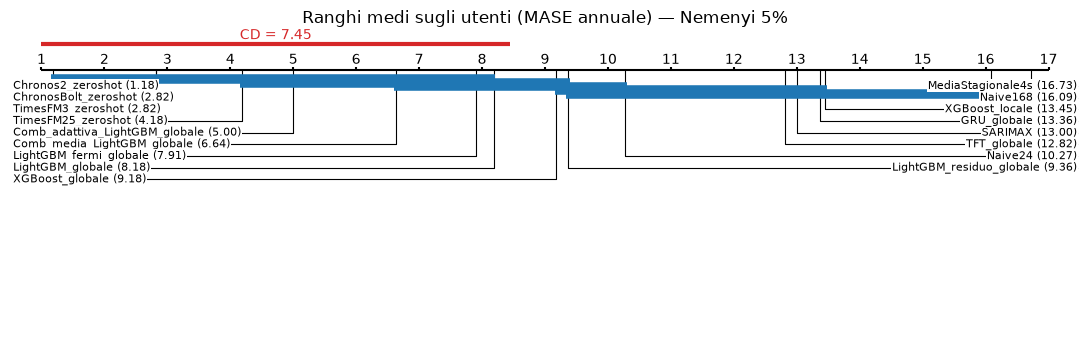

,model,mediana_diff,utenti_meglio,utenti,p,p_holm
0,Chronos2_zeroshot,-0.189864,11,11,0.000977,0.015625
13,TimesFM3_zeroshot,-0.173748,10,11,0.024414,0.219727
1,ChronosBolt_zeroshot,-0.173280,10,11,0.001953,0.023438
12,TimesFM25_zeroshot,-0.156973,10,11,0.018555,0.185547
2,Comb_adattiva_LightGBM_globale,-0.096357,11,11,0.000977,0.015625
3,Comb_media_LightGBM_globale,-0.081897,9,11,0.013672,0.150391
7,LightGBM_residuo_globale,-0.053150,7,11,0.519531,1.000000
14,XGBoost_globale,-0.046493,7,11,0.637695,1.000000
5,LightGBM_fermi_globale,-0.045442,7,11,0.413086,1.000000
6,LightGBM_globale,-0.043495,7,11,0.464844,1.000000


In [14]:
MAT = rob.matrix(SM)
FN = rob.friedman_nemenyi(MAT)
print(f"Friedman χ²={FN['chi2']:.2f}, p={FN['p_friedman']:.2g} | Iman-Davenport F={FN['F_iman_davenport']:.2f}, "
      f"p={FN['p_iman_davenport']:.2g} | N={FN['N']} utenti, k={FN['k']} modelli, CD={FN['cd']:.2f}")
fig, ax = plt.subplots(figsize=(11, 3.5))
rob.plot_cd(FN['avg_ranks'], FN['cd'], ax, 'Ranghi medi sugli utenti (MASE annuale) — Nemenyi 5%')
fig.tight_layout(); plt.show(); fig.savefig(ANA/'diagramma_cd.png', dpi=160, bbox_inches='tight')
WH = rob.wilcoxon_holm(MAT, REFERENCE)
display(WH); WH.to_csv(ANA/'wilcoxon_holm.csv', index=False)

### 5.4 Intervalli di confidenza bootstrap
Bootstrap a blocchi mobili sulle origini (7 origini consecutive = 14 giorni), uguali per tutti gli utenti e
modelli, così la dipendenza temporale e quella tra impianti restano nel campione. Se l'intervallo della
relMAE è tutto sotto 1, il miglioramento rispetto al riferimento è robusto alla scelta del periodo.

,model,relMAE_geom,IC95_inf,IC95_sup,sotto_1,sopra_1
0,Chronos2_zeroshot,0.813,0.783,0.850,True,False
1,ChronosBolt_zeroshot,0.833,0.800,0.871,True,False
13,TimesFM3_zeroshot,0.840,0.812,0.872,True,False
12,TimesFM25_zeroshot,0.864,0.826,0.904,True,False
2,Comb_adattiva_LightGBM_globale,0.899,0.883,0.922,True,False
3,Comb_media_LightGBM_globale,0.924,0.906,0.952,True,False
5,LightGBM_fermi_globale,0.977,0.944,1.029,False,False
6,LightGBM_globale,0.980,0.946,1.034,False,False
7,LightGBM_residuo_globale,0.987,0.956,1.036,False,False
14,XGBoost_globale,1.004,0.963,1.067,False,False


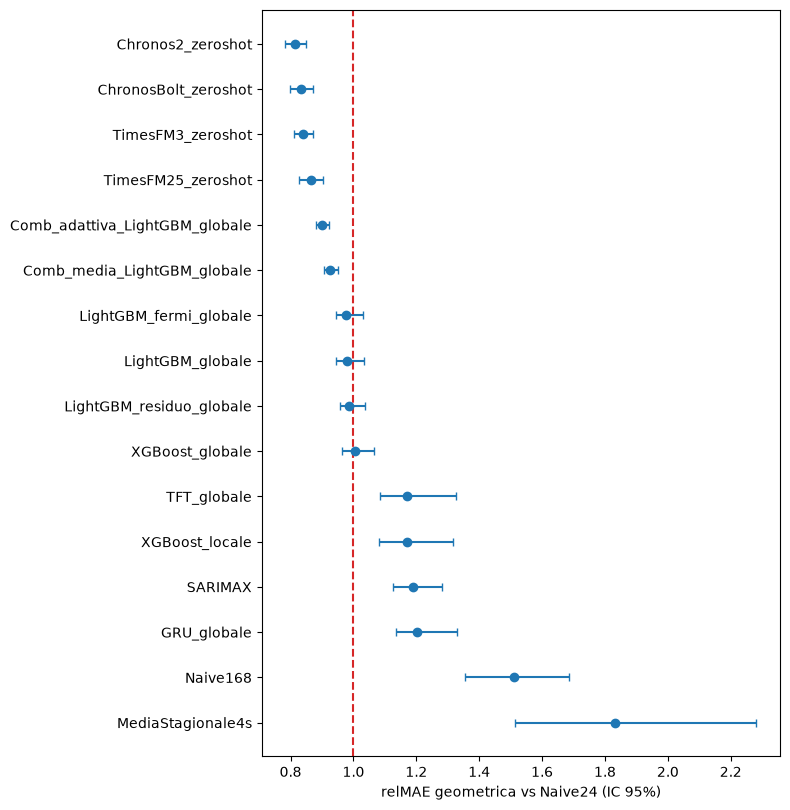

In [15]:
BOOT = rob.block_bootstrap_relmae(SM, REFERENCE, n_boot=200 if PROFILE == 'smoke' else 2000)
display(BOOT.style.format('{:.3f}', subset=['relMAE_geom', 'IC95_inf', 'IC95_sup']))
BOOT.to_csv(ANA/'bootstrap_relmae.csv', index=False)
fig, ax = plt.subplots(figsize=(8, .45*len(BOOT)+1))
y = np.arange(len(BOOT))
ax.errorbar(BOOT.relMAE_geom, y, xerr=np.clip([BOOT.relMAE_geom-BOOT.IC95_inf, BOOT.IC95_sup-BOOT.relMAE_geom], 0, None), fmt='o', capsize=3)
ax.axvline(1, color='tab:red', ls='--'); ax.set_yticks(y, BOOT.model); ax.invert_yaxis()
ax.set_xlabel(f'relMAE geometrica vs {REFERENCE} (IC 95%)'); fig.tight_layout(); plt.show()
fig.savefig(ANA/'bootstrap_relmae.png', dpi=160, bbox_inches='tight')

## 6. Tutti gli utenti e bias di selezione (punto 2)
### 6.1 Skill per utente
Skill = 1 − relMAE rispetto al riferimento (naive giornaliero). Il cerchio indica un risultato significativo con DM+Holm.
La mappa mostra subito se un modello funziona "in generale" o solo su alcuni impianti.

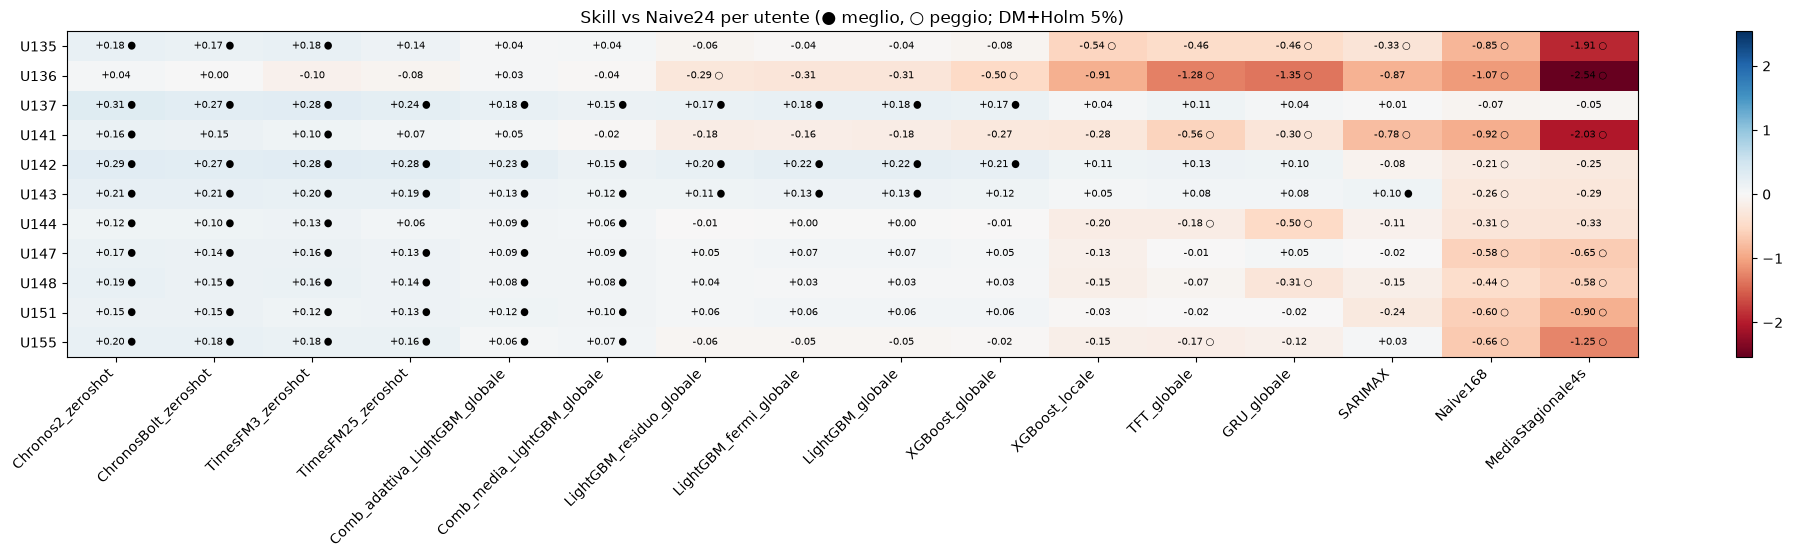

In [16]:
SKILL = (1-per_user.relMAE).unstack('model').drop(columns=REFERENCE, errors='ignore')
SKILL = SKILL[[c for c in board.index if c in SKILL.columns]]
sig = DMU.pivot(index='user', columns='model', values='esito').reindex(index=SKILL.index, columns=SKILL.columns)
fig, ax = plt.subplots(figsize=(1.1*SKILL.shape[1]+3, .38*len(SKILL)+1.5))
lim = np.nanmax(np.abs(SKILL.to_numpy()))
im = ax.imshow(SKILL.to_numpy(), cmap='RdBu', vmin=-lim, vmax=lim, aspect='auto')
for i in range(SKILL.shape[0]):
    for j in range(SKILL.shape[1]):
        mark = {'meglio': ' ●', 'peggio': ' ○'}.get(sig.iat[i, j], '')
        ax.text(j, i, f'{SKILL.iat[i, j]:+.2f}{mark}', ha='center', va='center', fontsize=7)
ax.set_xticks(range(SKILL.shape[1]), SKILL.columns, rotation=45, ha='right'); ax.set_yticks(range(len(SKILL)), SKILL.index)
ax.set_title(f'Skill vs {REFERENCE} per utente (● meglio, ○ peggio; DM+Holm 5%)')
fig.colorbar(im, ax=ax); fig.tight_layout(); plt.show()
fig.savefig(ANA/'skill_per_utente.png', dpi=160, bbox_inches='tight')
SKILL.to_csv(ANA/'skill_per_utente.csv')

### 6.2 Quanto conta la scelta dell'utente?
Per ogni modello si calcola la skill **in sviluppo** (validazione interna prima del test, la stessa usata per il
tuning) e la si confronta con la skill **sull'anno di test**:
- `ottimismo`: skill di test dell'utente migliore in sviluppo meno la media del pannello. È quanto si
  sovrastimerebbe il modello riportando solo l'utente scelto.
- `spearman_sviluppo_test`: se è basso, l'utente che sembra migliore in sviluppo non lo resta nel test.
- Rango e skill di `FOCUS_USER` (U155 nel notebook dei modelli profondi) rispetto al pannello.

In [17]:
t0 = pd.Timestamp(CFG['test_start'])
split = t0-pd.Timedelta(CFG['val_blocks']*CFG['horizon'], unit='h')
inner = pd.date_range(split, periods=CFG['val_blocks'], freq=f"{CFG['horizon']}h")
inner_by_user = {u: [o for o in inner if rob.window_ok(panel[u], o, CFG)] for u in USERS}
dev_mae = pd.DataFrame([dict(model=r['model'], user=r['user'], MAE=np.abs(r['actual']-r['pred']).mean())
                        for r in rob.baseline_forecasts(panel, inner_by_user, CFG)]).groupby(['user', 'model']).MAE.mean().unstack()
fit_scale = {u: rob.scaling(panel[u].loc[t0-pd.Timedelta(CFG['train_days'], unit='D'):split-pd.Timedelta(1, unit='h')])['scale'] for u in USERS}
dev_mase = dev_mae.div(pd.Series(fit_scale), axis=0)
for name, groups in tuning.items():
    for group, res in groups.items():
        for user, value in res['best']['dev_per_user'].items():
            dev_mase.loc[user, name] = value
# Skill indefinita se il naive ha errore nullo in sviluppo (impianto fermo): NaN, non ±inf.
DEV_SKILL = (1-dev_mase.div(dev_mase[REFERENCE], axis=0)).replace([np.inf, -np.inf], np.nan)
SEL = rob.selection_bias(DEV_SKILL, SKILL, focus=FOCUS_USER)
if len(SEL):
    display(SEL.set_index('model').style.format(precision=3))
else:
    print('Meno di 3 utenti con skill definita in sviluppo e test: analisi non calcolabile.')
SEL.to_csv(ANA/'bias_selezione.csv', index=False)

dev_rank = dev_mase.mean().rank(); test_rank = board.MASE_medio.rank()
common = dev_rank.index.intersection(test_rank.index)
from scipy.stats import spearmanr
rho, p = spearmanr(dev_rank[common], test_rank[common])
print(f'Concordanza tra classifica dei modelli in sviluppo e sull\'anno: Spearman {rho:.2f} (p={p:.2g})')
display(pd.DataFrame({'rango_sviluppo': dev_rank[common], 'rango_anno': test_rank[common]}).sort_values('rango_anno'))

,utenti,skill_test_pannello,skill_test_mediana,utente_migliore_sviluppo,skill_test_utente_scelto,ottimismo,spearman_sviluppo_test,p_spearman,skill_test_U155,rango_U155
model,,,,,,,,,,
LightGBM_residuo_globale,10,0.033,0.047,U148,0.042,0.009,0.552,0.098,-0.058,8
LightGBM_fermi_globale,10,0.044,0.049,U148,0.033,-0.012,0.624,0.054,-0.054,9
LightGBM_globale,10,0.042,0.047,U148,0.031,-0.011,0.624,0.054,-0.051,9
XGBoost_globale,10,0.028,0.044,U148,0.034,0.007,0.636,0.048,-0.023,8
XGBoost_locale,10,-0.129,-0.141,U148,-0.155,-0.026,0.285,0.425,-0.154,6
TFT_globale,10,-0.115,-0.043,U148,-0.066,0.048,0.661,0.038,-0.168,7
GRU_globale,10,-0.144,-0.071,U143,0.077,0.222,0.539,0.108,-0.122,6
Naive168,10,-0.489,-0.514,U148,-0.445,0.045,0.455,0.187,-0.659,8
MediaStagionale4s,10,-0.824,-0.614,U148,-0.579,0.245,0.527,0.117,-1.246,8


Concordanza tra classifica dei modelli in sviluppo e sull'anno: Spearman 0.39 (p=0.26)


,rango_sviluppo,rango_anno
model,,
LightGBM_residuo_globale,2.0,7.0
LightGBM_fermi_globale,3.0,8.0
Naive24,8.0,9.0
LightGBM_globale,4.0,10.0
XGBoost_globale,6.0,11.0
XGBoost_locale,9.0,12.0
TFT_globale,1.0,13.0
GRU_globale,7.0,14.0
Naive168,10.0,16.0


## 7. Sensibilità: senza Capodanno lunare e lockdown
Si ripetono classifica e bootstrap escludendo le origini nella finestra `ANOMALY`. Se le conclusioni cambiano,
vanno riportate entrambe: il comportamento nei periodi anomali è parte del problema industriale.

In [18]:
a0, a1 = map(pd.Timestamp, ANOMALY)
SM_normal = SM[(SM.origin+pd.Timedelta(CFG['horizon'], unit='h') <= a0) | (SM.origin > a1)]
if SM_normal.origin.nunique() >= 10:
    board_n, _ = rob.leaderboard(SM_normal, REFERENCE)
    cmp = board[['MASE_medio', 'relMAE_geom']].join(board_n[['MASE_medio', 'relMAE_geom']], rsuffix='_senza_anomalia')
    display(cmp.style.format('{:.3f}'))
    display(rob.block_bootstrap_relmae(SM_normal, REFERENCE, n_boot=200 if PROFILE == 'smoke' else 2000)
            .style.format('{:.3f}', subset=['relMAE_geom', 'IC95_inf', 'IC95_sup']))
else:
    print('Troppe poche origini fuori dalla finestra anomala con questo profilo.')

,MASE_medio,relMAE_geom,MASE_medio_senza_anomalia,relMAE_geom_senza_anomalia
model,,,,
Chronos2_zeroshot,0.944,0.813,1.087,0.806
ChronosBolt_zeroshot,0.971,0.833,1.121,0.829
TimesFM3_zeroshot,0.989,0.840,1.141,0.832
TimesFM25_zeroshot,1.007,0.864,1.152,0.849
Comb_adattiva_LightGBM_globale,1.035,0.899,1.190,0.894
Comb_media_LightGBM_globale,1.063,0.924,1.220,0.915
LightGBM_residuo_globale,1.137,0.987,1.300,0.971
LightGBM_fermi_globale,1.144,0.977,1.306,0.958
Naive24,1.145,1.000,1.321,1.000


,model,relMAE_geom,IC95_inf,IC95_sup,sotto_1,sopra_1
0,Chronos2_zeroshot,0.806,0.776,0.843,True,False
1,ChronosBolt_zeroshot,0.829,0.793,0.866,True,False
13,TimesFM3_zeroshot,0.832,0.805,0.861,True,False
12,TimesFM25_zeroshot,0.849,0.817,0.877,True,False
2,Comb_adattiva_LightGBM_globale,0.894,0.877,0.915,True,False
3,Comb_media_LightGBM_globale,0.915,0.897,0.942,True,False
5,LightGBM_fermi_globale,0.958,0.928,1.001,False,False
6,LightGBM_globale,0.960,0.929,1.005,False,False
7,LightGBM_residuo_globale,0.971,0.943,1.011,False,False
14,XGBoost_globale,0.974,0.942,1.020,False,False


## 8. Sintesi automatica
Frasi generate dai risultati, da verificare prima di usarle nella relazione.

In [19]:
best = board.index[0]
lines = [f"Pannello: {len(USERS)} utenze, {len(ORIGINS)} origini a 48 ore nel {TEST_YEAR}, {len(REFITS)} refit.",
         f"Migliore per MASE medio: {best} ({board.MASE_medio.iloc[0]:.3f})"
         + (", che è anche il riferimento." if best == REFERENCE else
            f"; riferimento {REFERENCE}: {board.loc[REFERENCE, 'MASE_medio']:.3f}.")]
for r in BOOT.itertuples():
    verdict = 'robustamente migliore' if r.sotto_1 else 'robustamente peggiore' if r.sopra_1 else 'non distinguibile'
    c = counts.loc[r.model] if r.model in counts.index else None
    extra = f"; meglio con DM in {c['meglio']}/{c.sum()} utenti, peggio in {c['peggio']}" if c is not None else ''
    lines.append(f"{r.model}: relMAE {r.relMAE_geom:.3f} [{r.IC95_inf:.3f}, {r.IC95_sup:.3f}] → {verdict} rispetto a {REFERENCE}{extra}.")
lines.append(f"Friedman p={FN['p_friedman']:.2g}; differenza critica di Nemenyi {FN['cd']:.2f} ranghi.")
if len(SEL):
    lines.append(f"Ottimismo medio scegliendo l'utente migliore in sviluppo: {SEL.ottimismo.mean():+.3f} di skill.")
print('\n'.join('- '+l for l in lines))
(ANA/'sintesi.md').write_text('\n'.join('- '+l for l in lines))

- Pannello: 11 utenze, 183 origini a 48 ore nel 2020, 14 refit.
- Migliore per MASE medio: Chronos2_zeroshot (0.944); riferimento Naive24: 1.145.
- Chronos2_zeroshot: relMAE 0.813 [0.783, 0.850] → robustamente migliore rispetto a Naive24; meglio con DM in 10/11 utenti, peggio in 0.
- ChronosBolt_zeroshot: relMAE 0.833 [0.800, 0.871] → robustamente migliore rispetto a Naive24; meglio con DM in 9/11 utenti, peggio in 0.
- TimesFM3_zeroshot: relMAE 0.840 [0.812, 0.872] → robustamente migliore rispetto a Naive24; meglio con DM in 10/11 utenti, peggio in 0.
- TimesFM25_zeroshot: relMAE 0.864 [0.826, 0.904] → robustamente migliore rispetto a Naive24; meglio con DM in 7/11 utenti, peggio in 0.
- Comb_adattiva_LightGBM_globale: relMAE 0.899 [0.883, 0.922] → robustamente migliore rispetto a Naive24; meglio con DM in 8/11 utenti, peggio in 0.
- Comb_media_LightGBM_globale: relMAE 0.924 [0.906, 0.952] → robustamente migliore rispetto a Naive24; meglio con DM in 8/11 utenti, peggio in 0.
- LightGB

2452